<a href="https://colab.research.google.com/github/furalmiqbadi/PembelajaranMesin_01_AbdulGhofurAlmiqbadi/blob/main/JS08/JS08_Tugas02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 0 - Persiapan Lingkungan

In [ ]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hdbscan

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

## Langkah 1 - Load Dataset

In [ ]:
# Load dataset
iris = load_iris()
X = iris.data
y_true = iris.target

print(f"Shape dataset: {X.shape}")
print(f"Fitur: {iris.feature_names}")
print(f"Label asli (target): {np.unique(y_true)}")

Shape dataset: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli (target): [0 1 2]


## Langkah 2 - Melakukan Clustering dengan HDBSCAN


In [ ]:
# Build model HDBSCAN
hdb = hdbscan.HDBSCAN(min_cluster_size=10)
cluster_labels = hdb.fit_predict(X)

# Simpan hasil ke dalam DataFrame untuk kemudahan analisis
df_result = pd.DataFrame(X, columns=iris.feature_names)
df_result['true_label'] = y_true
df_result['cluster'] = cluster_labels

## Langkah 3 - Melaporkan Hasil Clustering


In [ ]:
# Hitung jumlah cluster (mengabaikan noise yang berlabel -1)
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

# Hitung banyaknya noise
n_noise = list(cluster_labels).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya noise: {n_noise}")

Jumlah cluster yang terbentuk: 2
Banyaknya noise: 0


## Langkah 4 - Visualisasi Hasil Clustering

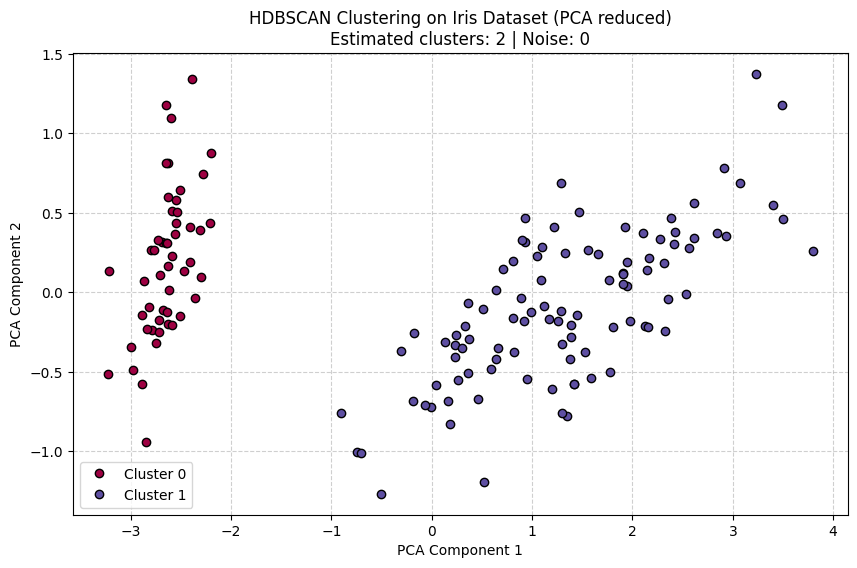

In [ ]:
# Reduksi dimensi menggunakan PCA (4D -> 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Visualisasi
plt.figure(figsize=(10, 6))
unique_labels = set(cluster_labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Warna hitam untuk noise

    class_member_mask = (cluster_labels == k)
    xy = X_pca[class_member_mask]

    plt.plot(
        xy[:, 0], xy[:, 1],
        'o' if k != -1 else 'x',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=6
    )

plt.title(f'HDBSCAN Clustering on Iris Dataset (PCA reduced)\nEstimated clusters: {n_clusters} | Noise: {n_noise}')
plt.xlabel(f'PCA Component 1')
plt.ylabel(f'PCA Component 2')

# Membuat legend
legend_labels = [f'Cluster {i}' if i != -1 else 'Noise' for i in unique_labels]
plt.legend(legend_labels, loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Analisis Singkat

- **Label Asli**: Dataset Iris secara asli memiliki **3 kelas** (*setosa, versicolor, virginica*).
- **Hasil HDBSCAN**: Model HDBSCAN berhasil menemukan **2** cluster dengan **0** data point yang teridentifikasi sebagai *noise*.
- **Kesesuaian**:
  - Hasil clustering HDBSCAN **kurang sesuai** dengan label asli. Hal ini disebabkan karena HDBSCAN sangat sensitif terhadap densitas, sehingga menggabungkan kelas *versicolor* dan *virginica* ke dalam satu cluster karena densitasnya yang saling berdekatan di ruang fitur.